In [3]:
#%pip install matplotlib

In [7]:
#%pip install seaborn

# Practice assignment 2

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [9]:
np.random.seed(0)

## Loading the dataset

In [10]:
from keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [12]:
# Print how much data you have
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape) 

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


Train data: **60,000** images of 28 x 28 size. 60k labels.
Test data: **10,000** images of 28 x 28 size.

## Visualize examples

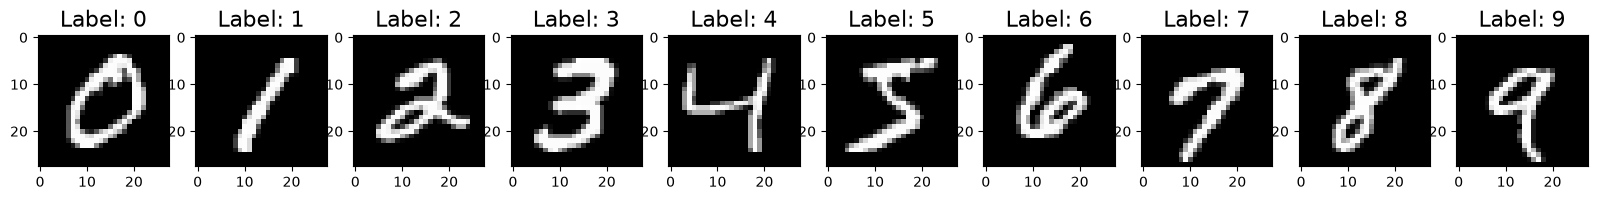

In [15]:
num_classes = 10
f, ax = plt.subplots(1, num_classes, figsize=(20, 20))

for i in range(0, num_classes):
    sample = x_train[y_train == i][0]
    ax[i].imshow(sample, cmap='gray')
    ax[i].set_title("Label: {}".format(i), fontsize=16)

In [16]:
for i in range(10):
    print(y_train[i])

5
0
4
1
9
2
1
3
1
4


In [17]:
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

In [18]:
for i in range(10):
    print(y_train[i])

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


**One-hot encoding** is done to convert the digit labels (0-9) into binary vectors of length 10.

Each vector contains a 1 at the position corresponding to the correct digit and 0s in all other positions. This makes it easier for the **Neural Network** to learn and classify the images into 10 different classes.

In addition, it also ensures that the digit labels are treated as separate categories rather than numerical values.

## Prepare the Data

We start by **normalizing the data**

In [19]:
x_train = x_train / 255.0
x_test = x_test / 255.0

Reshape the Data

In [22]:
x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

print(x_train.shape)

(60000, 784)


## Fully Connected Neural Network

In [24]:
model = Sequential()

model.add(Dense(
    units=128,
    input_shape=(784,),
    activation='relu'
))

model.add(Dense(units=128, activation='relu'))
model.add(Dropout(0.25))
model.add(Dense(units=10, activation='softmax'))

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

c:\Users\araz3\anaconda3\envs\nlp_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

## Train the Model

In [25]:
batch_size = 512
epochs = 10

model.fit(
    x=x_train,
    y=y_train,
    batch_size=batch_size,
    epochs=epochs
)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8253 - loss: 0.5998
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9364 - loss: 0.2181
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9548 - loss: 0.1582
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9635 - loss: 0.1250
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9697 - loss: 0.1035
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9733 - loss: 0.0904
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9771 - loss: 0.0775
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9796 - loss: 0.0674
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9820 - loss: 0.0586
Epoch 10/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9842 - loss: 0.0530


## Evaluate

In [26]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test Loss: {}, Test Accuracy: {}".format(test_loss, test_acc))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9761 - loss: 0.0749
Test Loss: 0.07494116574525833, Test Accuracy: 0.9761000275611877


In [27]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(y_pred)
print(y_pred_classes)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
[[2.6010384e-06 7.3625966e-07 3.1472850e-05 ... 9.9985898e-01
  9.5449968e-07 6.5516615e-06]
 [5.3047319e-08 2.6904940e-05 9.9995172e-01 ... 8.9840295e-09
  2.5139500e-06 4.4868536e-11]
 [1.0468780e-06 9.9869531e-01 1.5684764e-04 ... 9.2419062e-04
  9.5521726e-05 7.5346479e-06]
 ...
 [1.0397703e-09 3.5843456e-08 2.3671951e-10 ... 2.4183182e-05
  1.3094605e-06 1.3468558e-05]
 [2.5585504e-07 1.6870370e-06 9.0203587e-09 ... 1.6107372e-06
  1.7372910e-03 2.2962441e-08]
 [8.1786520e-06 2.7791239e-10 6.8885913e-07 ... 5.0782083e-11
  2.5825613e-09 9.2737714e-08]]
[7 2 1 ... 4 5 6]


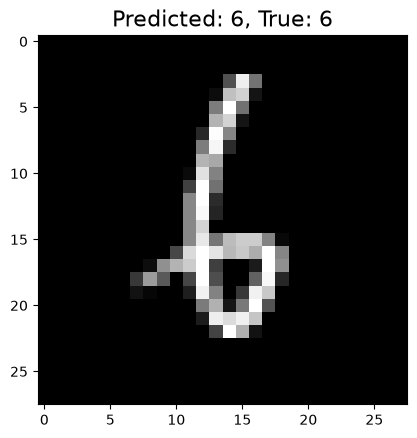

In [28]:
# Single Example
random_idx = np.random.choice(len(x_test))
x_sample = x_test[random_idx]
y_true = np.argmax(y_test, axis=1)
y_sample_true = y_true[random_idx]
y_sample_pred_class = y_pred_classes[random_idx]

plt.title("Predicted: {}, True: {}".format(y_sample_pred_class, y_sample_true), fontsize=16)
plt.imshow(x_sample.reshape(28, 28), cmap='gray')
plt.show()

## Confusion Matrix

In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred_classes)

Text(0.5, 1.0, 'Confusion matrix')

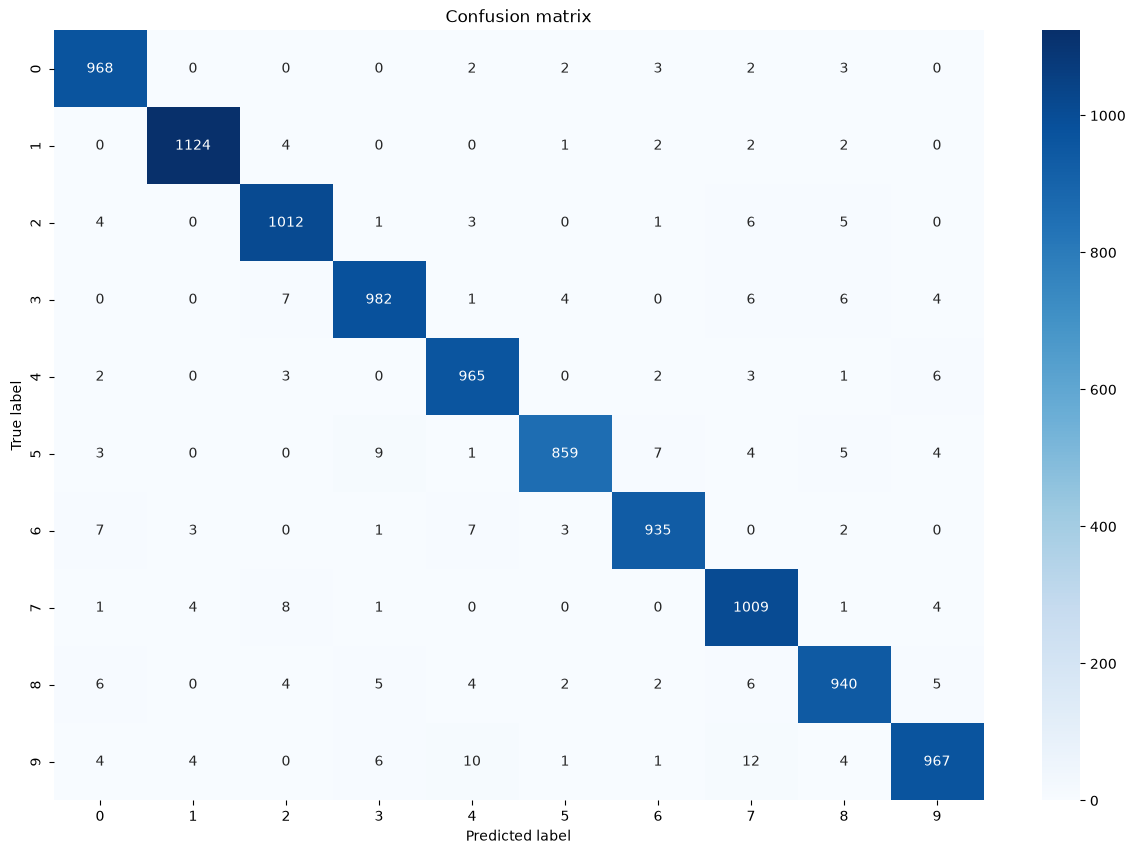

In [37]:
# Plot
fig, ax = plt.subplots(figsize=(15,10))
ax = sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    ax=ax,
    cmap='Blues'
)

ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion matrix')

## Investigating some of the Errors

In [38]:
errors = (y_pred_classes - y_true != 0)
y_pred_classes_errors = y_pred_classes[errors]

y_pred_errors = y_pred[errors]
y_true_errors = y_true[errors]
x_test_errors = x_test[errors]

In [39]:
y_pred_errors_probability = np.max(y_pred_errors, axis=1)
true_probability_errors = np.diagonal(np.take(y_pred_errors, y_true_errors, axis=1))
diff_errors_pred_true = y_pred_errors_probability - true_probability_errors

# Get list of indices of sorted differences
sorted_idx_diff_errors = np.argsort(diff_errors_pred_true)
top_idx_diff_errors = sorted_idx_diff_errors[-5:] # The 5 last ones


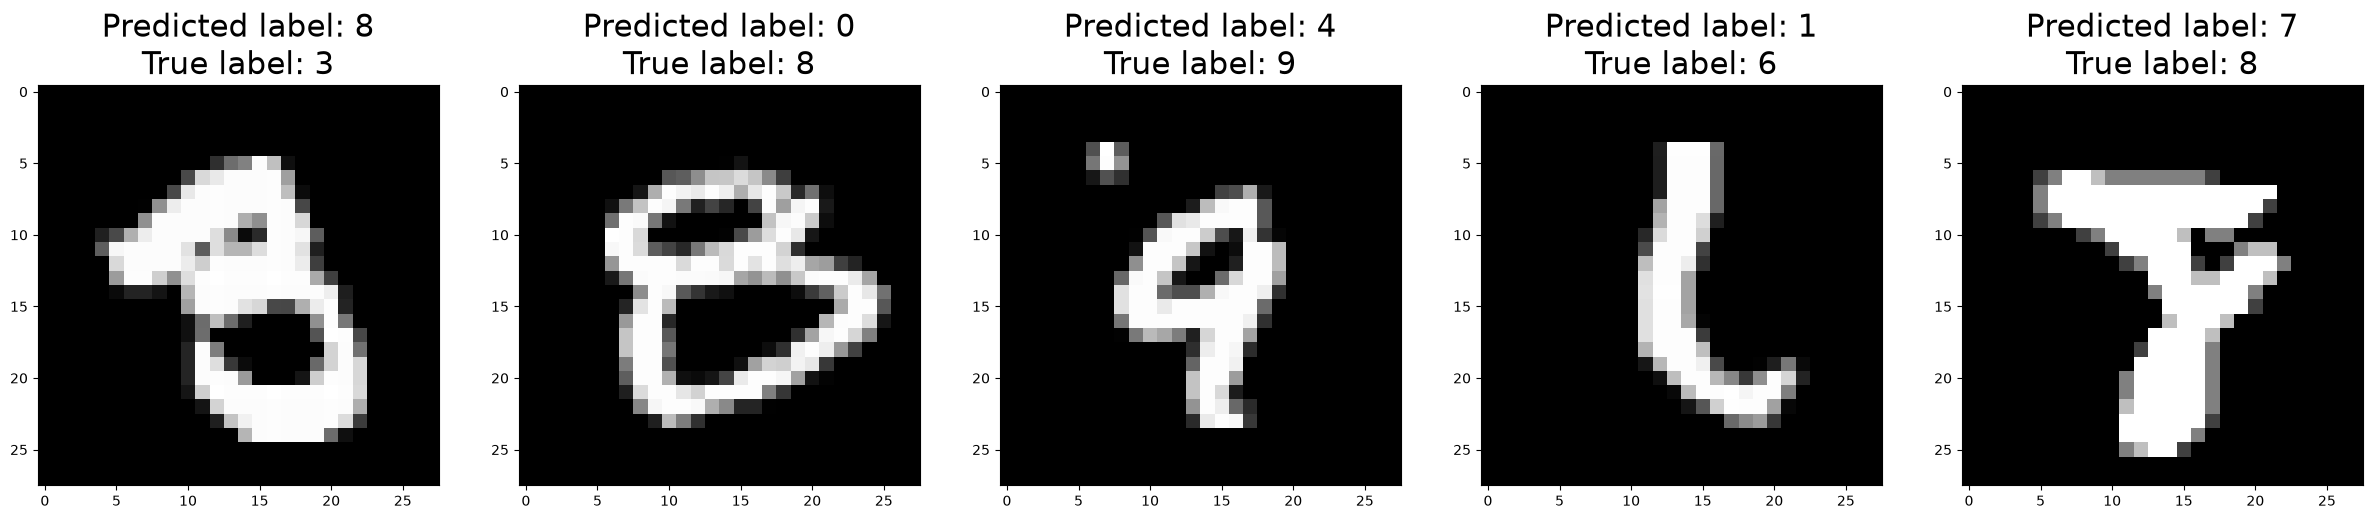

In [41]:
# Show top errors
num = len(top_idx_diff_errors)
f, ax = plt.subplots(1, num, figsize=(30, 30))

for i in range(0, num):
    idx = top_idx_diff_errors[i]
    sample = x_test_errors[idx].reshape(28, 28)
    y_t = y_true_errors[idx]
    y_p = y_pred_classes_errors[idx]
    ax[i].imshow(sample, cmap='gray')
    ax[i].set_title('Predicted label: {}\nTrue label: {}'.format(y_p, y_t), fontsize=22)